In [ ]:
!unzip "/content/drive/My Drive/split.zip" -d "/content/dataset"

Streaming output truncated to the last 5000 lines.
  inflating: /content/dataset/split/train/real/000000525013.jpg  
  inflating: /content/dataset/split/train/real/000000525043.jpg  
  inflating: /content/dataset/split/train/real/000000525122.jpg  
  inflating: /content/dataset/split/train/real/000000525156.jpg  
  inflating: /content/dataset/split/train/real/000000525159.jpg  
  inflating: /content/dataset/split/train/real/000000525257.jpg  
  inflating: /content/dataset/split/train/real/000000525279.jpg  
  inflating: /content/dataset/split/train/real/000000525291.jpg  
  inflating: /content/dataset/split/train/real/000000525330.jpg  
  inflating: /content/dataset/split/train/real/000000525343.jpg  
  inflating: /content/dataset/split/train/real/000000525366.jpg  
  inflating: /content/dataset/split/train/real/000000525403.jpg  
  inflating: /content/dataset/split/train/real/000000525410.jpg  
  inflating: /content/dataset/split/train/real/000000525454.jpg  
  inflating: /content/dat

In [ ]:
!unzip "/content/drive/My Drive/split2.zip" -d "/content/dataset"

Archive:  /content/drive/My Drive/split2.zip
  inflating: /content/dataset/split/test/real/-4kwwL-iZ2Q.jpg  
  inflating: /content/dataset/split/test/real/-djRG1vB1pw.jpg  
  inflating: /content/dataset/split/test/real/-lXcuISzufo.jpg  
  inflating: /content/dataset/split/test/real/-qwEUsg7UbI.jpg  
  inflating: /content/dataset/split/test/real/0aMMMUjiiEQ.jpg  
  inflating: /content/dataset/split/test/real/0Zx1bDv5BNY.jpg  
  inflating: /content/dataset/split/test/real/11GZVrMzfUU.jpg  
  inflating: /content/dataset/split/test/real/1qyw0De2XC8.jpg  
  inflating: /content/dataset/split/test/real/27ylvWv45Wc.jpg  
  inflating: /content/dataset/split/test/real/2k41e7OF8Rc.jpg  
  inflating: /content/dataset/split/test/real/2nX4pShh5JE.jpg  
  inflating: /content/dataset/split/test/real/2OalKAckLvU.jpg  
  inflating: /content/dataset/split/test/real/3kkQCmJpFlY.jpg  
  inflating: /content/dataset/split/test/real/3pffLvHFej8.jpg  
  inflating: /content/dataset/split/test/real/3RdHg46F-q0.j

In [ ]:
!pip install tensorflow seaborn matplotlib scikit-learn

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

In [ ]:
# Check if GPU is available
print("Num GPUs Available:", len(tf.config.experimental.list_physical_devices('GPU')))

Num GPUs Available: 1


In [ ]:
# Image settings
IMG_SIZE = 380
BATCH_SIZE = 32

# Dataset directories
train_dir = "/content/dataset/split/train"
val_dir = "/content/dataset/split/val"
test_dir = "/content/dataset/split/test"

# Rescaling for training, validation, and testing (no augmentation)
datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255)

# Data generators (no augmentation)
train_generator = datagen.flow_from_directory(
    train_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=True
)

val_generator = datagen.flow_from_directory(
    val_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)

test_generator = datagen.flow_from_directory(
    test_dir,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='binary',
    shuffle=False
)


Found 29601 images belonging to 2 classes.
Found 3781 images belonging to 2 classes.
Found 3784 images belonging to 2 classes.


In [ ]:
from tensorflow.keras import layers, models

# Define custom CNN with Input layer
model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(2, 2),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(1, activation='sigmoid')
])

# Compile model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=['accuracy'])


In [ ]:
# Callbacks for early stopping and learning rate reduction
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss', factor=0.2, patience=2, min_lr=1e-6
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'best_model.h5', monitor='val_loss', save_best_only=True, mode='min', verbose=1
)

# Train the model
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,  # Adjust as needed
    callbacks=[early_stopping, reduce_lr, checkpoint]
)


Epoch 1/10
926/926 ━━━━━━━━━━━━━━━━━━━━ 0s 366ms/step - accuracy: 0.7728 - loss: 0.4706
Epoch 1: val_loss improved from inf to 0.33112, saving model to best_model.h5


926/926 ━━━━━━━━━━━━━━━━━━━━ 383s 413ms/step - accuracy: 0.7728 - loss: 0.4705 - val_accuracy: 0.8545 - val_loss: 0.3311 - learning_rate: 1.0000e-04
Epoch 2/10
926/926 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step - accuracy: 0.8745 - loss: 0.3005
Epoch 2: val_loss improved from 0.33112 to 0.28749, saving model to best_model.h5


926/926 ━━━━━━━━━━━━━━━━━━━━ 405s 437ms/step - accuracy: 0.8745 - loss: 0.3005 - val_accuracy: 0.8810 - val_loss: 0.2875 - learning_rate: 1.0000e-04
Epoch 3/10
926/926 ━━━━━━━━━━━━━━━━━━━━ 0s 341ms/step - accuracy: 0.8898 - loss: 0.2698
Epoch 3: val_loss did not improve from 0.28749
926/926 ━━━━━━━━━━━━━━━━━━━━ 357s 386ms/step - accuracy: 0.8898 - loss: 0.2698 - val_accuracy: 0.5990 - val_loss: 1.2403 - learning_rate: 1.0000e-04
Epoch 4/10
926/926 ━━━━━━━━━━━━━━━━━━━━ 0s 331ms/step - accuracy: 0.8970 - loss: 0.2565
Epoch 4: val_loss did not improve from 0.28749
926/926 ━━━━━━━━━━━━━━━━━━━━ 341s 368ms/step - accuracy: 0.8970 - loss: 0.2565 - val_accuracy: 0.6771 - val_loss: 0.7467 - learning_rate: 1.0000e-04
Epoch 5/10
926/926 ━━━━━━━━━━━━━━━━━━━━ 0s 321ms/step - accuracy: 0.9131 - loss: 0.2168
Epoch 5: val_loss did not improve from 0.28749
926/926 ━━━━━━━━━━━━━━━━━━━━ 330s 357ms/step - accuracy: 0.9131 - loss: 0.2168 - val_accuracy: 0.8450 - val_loss: 0.4284 - learning_rate: 2.0000e-05

In [ ]:
# Check if TensorFlow is using the GPU
from tensorflow.python.client import device_lib
device_lib.list_local_devices()


[name: "/device:CPU:0"
 device_type: "CPU"
 memory_limit: 268435456
 locality {
 }
 incarnation: 7137975120865492259
 xla_global_id: -1,
 name: "/device:GPU:0"
 device_type: "GPU"
 memory_limit: 14619377664
 locality {
   bus_id: 1
   links {
   }
 }
 incarnation: 8920085414846146319
 physical_device_desc: "device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5"
 xla_global_id: 416903419]

In [ ]:
# Save the trained model in .keras format
best_model.save('final_model.keras')

# To verify if it's saved
print("Model saved as final_model.keras")


Model saved as final_model.keras


In [ ]:
# Load the model from the .keras file
loaded_model = tf.keras.models.load_model('final_model.keras')

# Verify if the model is loaded correctly
print("Model loaded successfully from final_model.keras")


Model loaded successfully from final_model.keras


/usr/local/lib/python3.11/dist-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 42 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


119/119 ━━━━━━━━━━━━━━━━━━━━ 34s 278ms/step - accuracy: 0.8449 - loss: 0.3387
Test Accuracy: 0.8819, Test Loss: 0.2746
119/119 ━━━━━━━━━━━━━━━━━━━━ 36s 296ms/step


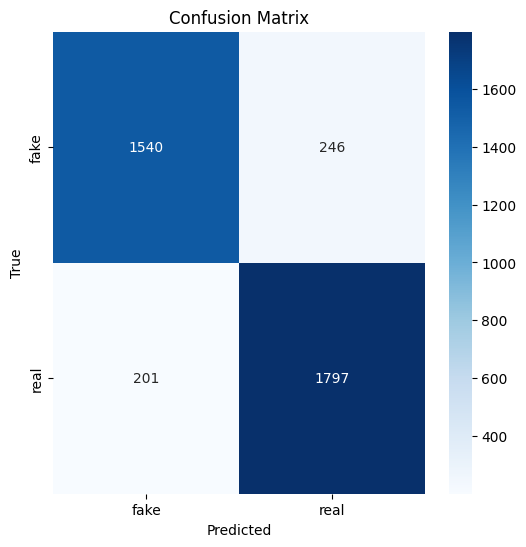

              precision    recall  f1-score   support

        fake       0.88      0.86      0.87      1786
        real       0.88      0.90      0.89      1998

    accuracy                           0.88      3784
   macro avg       0.88      0.88      0.88      3784
weighted avg       0.88      0.88      0.88      3784



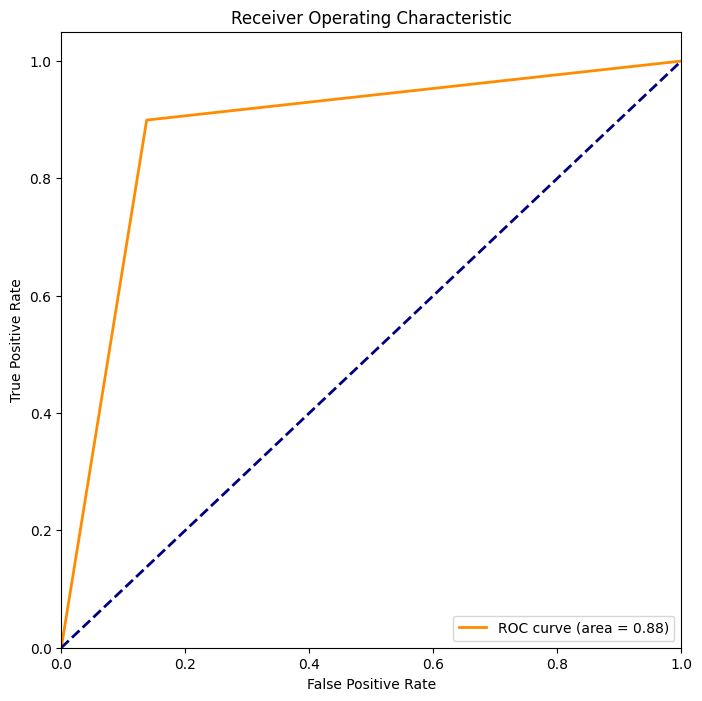

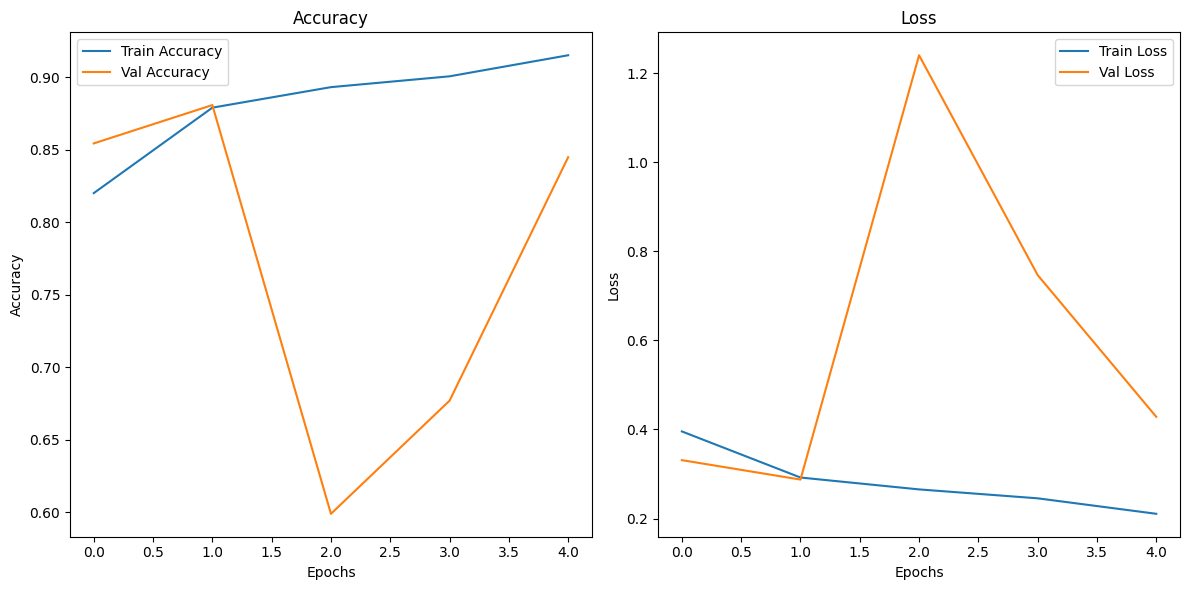

In [ ]:
# Load the best model (if using model checkpointing)
best_model = tf.keras.models.load_model("best_model.h5")

# Evaluate on the test set
test_loss, test_acc = best_model.evaluate(test_generator)
print(f"Test Accuracy: {test_acc:.4f}, Test Loss: {test_loss:.4f}")

# Get true labels and predictions for confusion matrix and ROC curve
test_labels = test_generator.classes
predictions = best_model.predict(test_generator, verbose=1)
predictions = (predictions > 0.5).astype(int)  # Binarize predictions

# Confusion Matrix
cm = confusion_matrix(test_labels, predictions)
plt.figure(figsize=(6,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=test_generator.class_indices.keys(), yticklabels=test_generator.class_indices.keys())
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Classification Report (Precision, Recall, F1)
print(classification_report(test_labels, predictions, target_names=test_generator.class_indices.keys()))

# ROC Curve and AUC
fpr, tpr, thresholds = roc_curve(test_labels, predictions)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8,8))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc='lower right')
plt.show()

# Training & Validation Accuracy / Loss Plot
plt.figure(figsize=(12, 6))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()
